# 01 — Preprocessing · Raghavan et al. 2021 (Pancreatic Ductal Adenocarcinoma, Seq-Well)
Load malignant cells → restrict to the declared disease (PDAC; a neuroendocrine PANET sample is a distinct malignancy and is excluded) → derive a per-sample cell floor → overdispersed genes → PCA → Harmony(sample) → neighbours/UMAP → island removal → lobe biology (cell cycle, Moffitt subtype, developmental modules) → **Gate 1** on the regenerated embedding (iLISI mixing + continuity).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (one level deeper than Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Raghavan2021_Pancreas | category: Pancreas


### Load malignant cells; check disease/site composition
Raghavan 2021 is a **metastatic** PDAC atlas (biopsies, mostly liver). The malignant compartment also contains one **PANET** (pancreatic neuroendocrine tumour) sample — a different cancer of origin. The dataset is declared PDAC in `CCCA_summary.csv`, so the analysis is scoped to PDAC.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('disease composition:', adata.obs['disease'].value_counts().to_dict())
print('metastatic site composition:', adata.obs['source'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Raghavan2021_Pancreas
Done.
full atlas: (24412, 16814)
malignant: (7904, 16814) | samples: 23
disease composition: {'PDAC': 7242, 'PANET': 662}
metastatic site composition: {'Liver': 6778, 'Omentum': 931, 'Adrenal gland': 120, 'Lung': 46, 'Peritoneum': 29}
expression: X max 7.61 (log1p of normalize_total UMI counts)


### Scope to the declared disease (PDAC)
The PANET cells come from a single sample (100% neuroendocrine) — a distinct malignancy, not a PDAC cell state. Keeping it would contaminate the developmental-module read with a different lineage (the Kürten lobe-identity lesson: settle each sub-region biology and scope to the region reproducing the reference relationships). Dropping it leaves a clean PDAC study.

In [4]:
comp = (adata.obs.groupby('sample', observed=True)['disease']
        .agg(n='size', panet=lambda s:(s=='PANET').sum()))
comp['pct_panet'] = (comp['panet']/comp['n']*100).round(0)
print('samples that are majority PANET:', list(comp.index[comp.pct_panet>50]))
n_panet = int((adata.obs['disease']=='PANET').sum())
adata = adata[adata.obs['disease']=='PDAC'].copy()
print(f'dropped {n_panet} PANET cells -> {adata.shape[0]} PDAC cells across {adata.obs["sample"].nunique()} samples')

samples that are majority PANET: ['PANFR0580_Biopsy_None']
dropped 662 PANET cells -> 7242 PDAC cells across 22 samples


### Derive per-sample cell floor from the count distribution
Sort per-sample counts; find the largest **multiplicative** gap and require it to be a clean cliff (ratio-of-ratios vs the runner-up ≥ 1.5). Here the gap 120→45 (ratio 2.67) clears the runner-up (1.56) by RoR 1.71, so it is a real inflection — cut at the geometric mean across it.

In [5]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
order = np.argsort(ratios)[::-1]
gap = int(order[0]); ror = ratios[order[0]] / ratios[order[1]]
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}); runner-up ratio {ratios[order[1]]:.2f}; ratio-of-ratios {ror:.2f}')
FLOOR = 100
if gap == 0 or ror < 1.5:
    thresh = FLOOR
    print(f'gap not a dominant cliff -> fall back to >= {FLOOR}-cell floor')
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant cliff -> derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[keep].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [1053  674  612  574  555  516  390  376  322  260  250  237  229  208
  197  164  159  143  129  120   45   29]
largest multiplicative gap: 120 -> 45 (ratio 2.67); runner-up ratio 1.56; ratio-of-ratios 1.71
dominant cliff -> derived threshold (geometric mean across the gap) = 73
kept 20/22 samples (min per-sample = 120) -> 7168 cells


### Gene filter → overdispersed selection → PCA → Harmony integration
Integration strength swept (θ = 2/5/10) with a same-sample-neighbour-fraction diagnostic; select the θ that drives per-neighbourhood mixing to its plateau. `n_pcs=20` derived to the atlas scale (the Puram-40 / Kürten-20 precedents); `spread=1.3`.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1308 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1308
same-sample neighbour fraction | pre-Harmony 0.938 | sweep {2: 0.267, 5: 0.258, 10: 0.264}
selected theta = 10 (mixing plateaus by theta=5; strongest integration without collapse)


### Remove detached islands (radius-graph connected components)
Radius graph at 6× median nearest-neighbour distance; keep the largest connected component. Strictly conservative — only disconnected specks are stripped.

In [7]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('cells on the main component:', adata.shape[0])

removed 0 cells in 0 detached islands
cells on the main component: 7168


### Sub-region biology *before* Gate 1 — cell cycle + Moffitt subtype
Leiden (res 0.15) resolves two lobes. Characterise each by proliferation and by the Moffitt et al. (2015) classical/basal PDAC programmes — the biological check the spec requires before certifying the manifold. The lobes split by **cell cycle**, both are classical-predominant (basal ≈ 0); this is a PDAC proliferation axis, not two lineages.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','CEACAM5','TSPAN8','ST6GALNAC1','AGR2',
             'CLRN3','LYZ','MYO1A','CDH17','VSIG2','BTNL8','FAM3D','SPINK4']
basal = ['KRT17','KRT15','KRT6A','KRT6C','KRT5','KRT7','KRT14','TP63','S100A2','SPRR3','SPRR1B',
         'LY6D','SCEL','FAM83A','SLC2A1','CST6','DHRS9','LEMD1','GPR87']
for nm,gs in [('classical',classical),('basal',basal)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())
cl = adata.obs.groupby('lobe', observed=True)['classical_score'].mean()
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
prolif_lobe = cyc.idxmax()
lab_map = {l: ('Cycling' if l==prolif_lobe else 'Ductal-body') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 4323, '0': 2171, '2': 674}
overall cycling fraction: 0.166
cycling fraction per lobe: {'0': 0.104, '1': 0.087, '2': 0.871}
classical: 17/17 genes | per-lobe mean {'0': 0.148, '1': 0.264, '2': 0.121}
basal: 18/19 genes | per-lobe mean {'0': 0.038, '1': 0.046, '2': 0.056}
compartments: {'Ductal-body': 6494, 'Cycling': 674}


### Developmental modules + house linear orientation
Score Gast/pSom/Crest (union control pool) for the orientation sign only (02 re-scores canonically). A single elongated developmental axis dominates variation even though the overall cloud is roughly round; store a **rigid rotation** of the UMAP (distances preserved) with the somitogenesis-high developmental origin on the left, as `X_umap_lin`, so every panel shares one orientation.

In [9]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]                       # pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)     # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],
               [np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'somitogenesis-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.14
house orientation: rigid rotation +162.3deg (distances preserved), somitogenesis-high origin pole on left; stored as X_umap_lin


### Gate 1 — mixing + continuity on the regenerated embedding
Judge Gate 1 on the embedding, not a single scalar: per-neighbourhood **iLISI** (effective number of samples in each cell neighbourhood) before vs after Harmony, and the connectivity of the manifold (one component after island removal). Both lobes contain many samples.

In [10]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 7.22 of 20 samples
20 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save `processed.h5ad`

In [11]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7168, 16763)


### Deliverable figure — `samples.pdf`
House style (figsize (3.5, 1.5), size 30) on the shared orientation (`X_umap_lin`). Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 7168


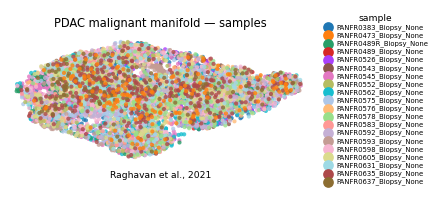

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])